In [13]:
import numpy
import matplotlib.pyplot as plt
import gdown
from pathlib import Path

In [ ]:


data_dir = Path("../data/raw")
data_dir.mkdir(parents=True, exist_ok=True)

# Dane treningowe
gdown.download(
    id="1KC8FBlCuwh9ITUt0CcPeRJCpqy5j4WBp",
    output=str(data_dir / "train.pkl"),
    quiet=False
)

# Dane walidacyjne
gdown.download(
    id="1Oza4UjnmAUeae2cA8YDwMWxVHOb7SKdP",
    output=str(data_dir / "val.pkl"),
    quiet=False
)


Downloading...
From: https://drive.google.com/uc?id=1KC8FBlCuwh9ITUt0CcPeRJCpqy5j4WBp
To: /Users/patryknisgorski/_aii/data/raw/train.pkl
100%|██████████| 52.0M/52.0M [00:00<00:00, 80.5MB/s]
Downloading...
From: https://drive.google.com/uc?id=1Oza4UjnmAUeae2cA8YDwMWxVHOb7SKdP
To: /Users/patryknisgorski/_aii/data/raw/val.pkl
100%|██████████| 18.0M/18.0M [00:00<00:00, 55.7MB/s]


'../data/raw/val.pkl'

In [9]:
import pickle

with open("../data/raw/train.pkl", "rb") as f:
    data = pickle.load(f)

print(type(data))
print(len(data))
print(type(data[0]))
print(data[0].keys())

<class 'list'>
52
<class 'dict'>
dict_keys(['image', 'boxes', 'labels'])


In [11]:
for key, value in data[0].items():
    print(key, type(value))

image <class 'PIL.Image.Image'>
boxes <class 'torch.Tensor'>
labels <class 'torch.Tensor'>


Rozmiar zdjęcia: (640, 520)
Liczba monet: 8
Bounding boxy: tensor([[264,  49, 342, 128],
        [172, 167, 238, 233],
        [346, 144, 411, 210],
        [249, 356, 310, 416],
        [388, 401, 447, 462],
        [228, 254, 280, 303],
        [419, 239, 470, 290],
        [306, 272, 373, 340]])
Klasy monet: tensor([8, 5, 5, 4, 4, 0, 3, 7])


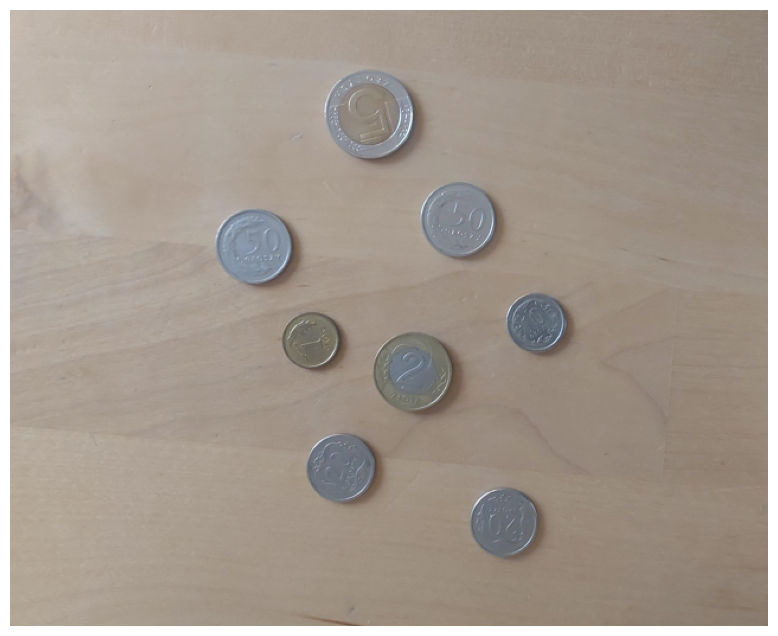

In [14]:
sample = data[0]

image = sample["image"]
boxes = sample["boxes"]
labels = sample["labels"]

print("Rozmiar zdjęcia:", image.size)
print("Liczba monet:", len(boxes))
print("Bounding boxy:", boxes)
print("Klasy monet:", labels)

plt.figure(figsize=(10, 8))
plt.imshow(image)
plt.axis("off")
plt.show()

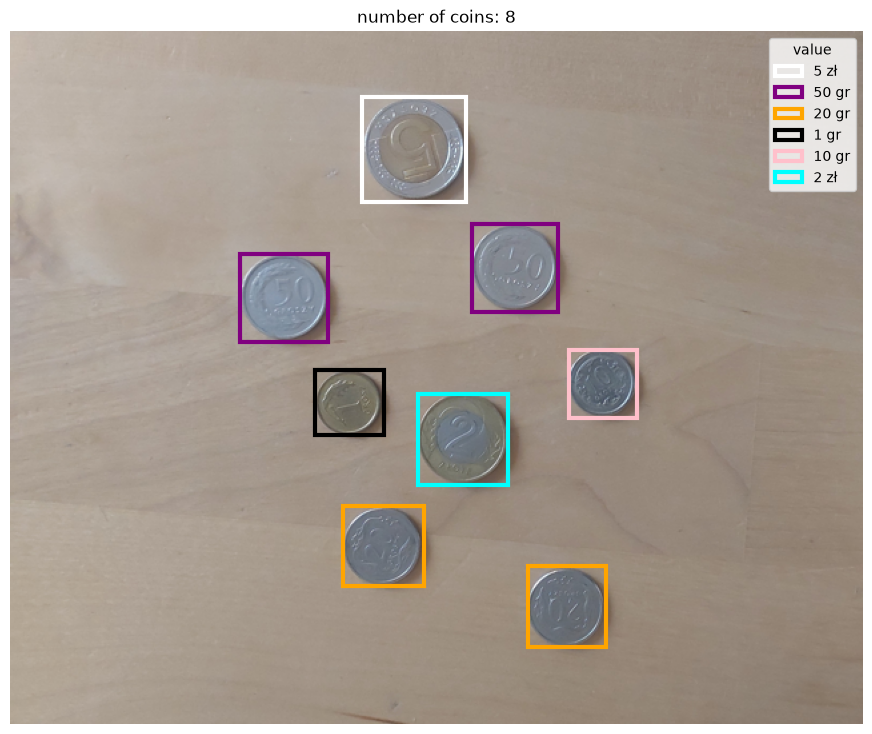

In [37]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

sample = data[0]

image = sample["image"]
boxes = sample["boxes"]
labels = sample["labels"]

CLASS_NAMES = [
    "1 gr", "2 gr", "5 gr",
    "10 gr", "20 gr", "50 gr",
    "1 zł", "2 zł", "5 zł"
]

colors = {
    0: "black",
    1: "red",
    2: "blue",
    3: "pink",
    4: "orange",
    5: "purple",
    6: "green",
    7: "cyan",
    8: "white",
    9: "black"

}

fig, ax = plt.subplots(figsize=(12, 9))

ax.imshow(image)

for box, label in zip(boxes, labels):
    x1, y1, x2, y2 = box.tolist()
    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        edgecolor=colors[int(label)],
        linewidth=3,
        facecolor="none",
        label=CLASS_NAMES[int(label)]
    )
    ax.add_patch(rect)

handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles))

ax.legend(unique.values(), unique.keys(), title="value")
ax.set_title(f"number of coins: {len(boxes)}")
ax.axis("off")
plt.show()